In [27]:
import sys, sklearn, ipykernel
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
print(sys.version)
print(sys.executable)
print("Setup OK!")

print('test data cleaning')

print('hi')

ImportError: sklearn._cyutility does not export expected C function slice_memviewslice

In [28]:
diabetic_data = pd.read_csv('diabetic_data.csv',  na_values = ['?'], keep_default_na = False)
IDS_mapping = pd.read_csv('IDS_mapping.csv', na_values = ['?'], keep_default_na = False)

/var/folders/t2/z2d0j1ns56l8gkc11rwm53pw0000gn/T/ipykernel_38771/2938591321.py:1: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  diabetic_data = pd.read_csv('diabetic_data.csv',  na_values = ['?'], keep_default_na = False)


In [29]:
diabetic_data_3 = diabetic_data
diabetic_data_3.shape

(101766, 50)

In [30]:
#Nateglinide
print(diabetic_data_3['nateglinide'].value_counts(normalize= True))

#chlorpropamide
print(diabetic_data_3['chlorpropamide'].value_counts(normalize=True)) #>99.9

#acetohexamide
print(diabetic_data_3['acetohexamide'].value_counts(normalize=True)) #>99.9

#tolbutamide
print(diabetic_data_3['tolbutamide'].value_counts(normalize=True)) #>99.9

#acarbose
print(diabetic_data_3['acarbose'].value_counts(normalize=True)) 

#miglitol
print(diabetic_data_3['miglitol'].value_counts(normalize=True)) #>99.9

#troglitazone
print(diabetic_data_3['troglitazone'].value_counts(normalize=True)) #99.9

#tolazamide
print(diabetic_data_3['tolazamide'].value_counts(normalize=True)) #>99.9

#glyburide-metformin
print(diabetic_data_3['glyburide-metformin'].value_counts(normalize=True))

#glipizide-metformin
print(diabetic_data_3['glipizide-metformin'].value_counts(normalize=True)) #>99.9

#glimepiride-pioglitazone
print(diabetic_data_3['glimepiride-pioglitazone'].value_counts(normalize=True)) #>99.9

#metformin-rosiglitazone
print(diabetic_data_3['metformin-rosiglitazone'].value_counts(normalize=True)) #>99.9

#metformin-pioglitazone
print(diabetic_data_3['metformin-pioglitazone'].value_counts(normalize=True)) #>99.9



nateglinide
No        0.993092
Steady    0.006564
Up        0.000236
Down      0.000108
Name: proportion, dtype: float64
chlorpropamide
No        0.999155
Steady    0.000776
Up        0.000059
Down      0.000010
Name: proportion, dtype: float64
acetohexamide
No        0.99999
Steady    0.00001
Name: proportion, dtype: float64
tolbutamide
No        0.999774
Steady    0.000226
Name: proportion, dtype: float64
acarbose
No        0.996973
Steady    0.002899
Up        0.000098
Down      0.000029
Name: proportion, dtype: float64
miglitol
No        0.999627
Steady    0.000305
Down      0.000049
Up        0.000020
Name: proportion, dtype: float64
troglitazone
No        0.999971
Steady    0.000029
Name: proportion, dtype: float64
tolazamide
No        0.999617
Steady    0.000373
Up        0.000010
Name: proportion, dtype: float64
glyburide-metformin
No        0.993063
Steady    0.006800
Up        0.000079
Down      0.000059
Name: proportion, dtype: float64
glipizide-metformin
No        0.999872


In [31]:
diabetic_data_4 = diabetic_data_3

<h1><u> Encoding </u></h1>
<h3>Encoding the 'gender', 'age' and 'admission_type_id'</h3>

<i>What is it for?</i> To turn text into numbers for the models to be able to work.





In [32]:


diabetic_data_4['gender'] = diabetic_data_4['gender'].map({
    'Male': 0,
    'Female': 1
})


diabetic_data_4['admission_type_id'] = diabetic_data_4['admission_type_id'].replace({
    1: 'Emergency',
    2: 'Urgent',
    3: 'Elective',
    4: 'Newborn',
    5: 'unknown',
    6: 'unknown',
    8: 'unknown',
    7: 'Trauma Center'
})

<h3> admission_source_id encoding </h3>
The numbered values were changed into their description, so that one hot encoding could group them easily. Any value that did not have a count of over 100 went into the other category.

In [33]:
print(diabetic_data_4['admission_source_id'].unique())
print(diabetic_data_4['admission_source_id'].value_counts)

diabetic_data_4['admission_source_id'] = diabetic_data_4['admission_source_id'].replace({
    1: 'Physician Referral',
    2: 'Clinic Referral',
    3: 'HMO Referral',
    4: 'Transfer from a hospital',
    5: 'Transfer from a Skilled Nursing Facility (SNF)',
    6: 'Transfer from another health care facility',
    7: 'Emergency Room',
    8: 'other',
    9: 'unknown',
    10: 'other',
    11: 'other',
    12: 'Premature Delivery',
    13: 'other',
    14: 'other',
    15: 'unknown',
    16: 'unknown',
    17: 'unknown',
    18: 'Transfer From Another Home Health Agency',
    19: 'Readmission to Same Home Health Agency',
    20: 'unknown',
    21: 'unknown',
    22: 'other',
    23: 'Born inside this hopsital',
    24: 'Born outside this hospital',
    25: 'other',
    26: 'Transfer from Hospice'

})

[ 1  7  2  4  5  6 20  3 17  8  9 14 10 22 11 25 13]
<bound method IndexOpsMixin.value_counts of 0         1
1         7
2         7
3         7
4         7
         ..
101761    7
101762    5
101763    7
101764    7
101765    7
Name: admission_source_id, Length: 101766, dtype: int64>


<h3>Encoding medical_specialty</h3>

In [34]:
print(diabetic_data_4['medical_specialty'].unique())
print(diabetic_data_4['medical_specialty'].value_counts)

diabetic_data_4['medical_specialty'] = diabetic_data_4['medical_specialty'].fillna('unknown')
diabetic_data_4['medical_specialty'] = diabetic_data_4['medical_specialty'].replace({
    'Surgery-General': 'surgery',
    'Surgery-Cardiovascular/Thoracic': 'surgery',
    'Surgery-Neuro': 'surgery',
    'Surgery-Colon&Rectal': 'surgery',
    'Surgery-Thoracic': 'surgery',
    'Surgery-Vascular': 'surgery',
    'Surgery-Plastic': 'surgery',
    'Surgery-Cardiovascular': 'surgery',
    'Surgery-Maxillofacial': 'surgery',
    'Surgery-Pediatric': 'surgery',
    'Surgery-PlasticwithinHeadandNeck': 'surgery'
})


<StringArray>
[            'Pediatrics-Endocrinology',
                                    nan,
                     'InternalMedicine',
               'Family/GeneralPractice',
                           'Cardiology',
                      'Surgery-General',
                          'Orthopedics',
                     'Gastroenterology',
      'Surgery-Cardiovascular/Thoracic',
                           'Nephrology',
           'Orthopedics-Reconstructive',
                           'Psychiatry',
                     'Emergency/Trauma',
                          'Pulmonology',
                        'Surgery-Neuro',
 'Obsterics&Gynecology-GynecologicOnco',
              'ObstetricsandGynecology',
                           'Pediatrics',
                  'Hematology/Oncology',
                       'Otolaryngology',
                 'Surgery-Colon&Rectal',
              'Pediatrics-CriticalCare',
                        'Endocrinology',
                              'Urology',
  

In [36]:
categorical_columns = ['age', 'admission_type_id', 'admission_source_id']
diabetic_data_encoded = pd.get_dummies(
    diabetic_data_4,
    columns = categorical_columns,
    dtype=int,
    drop_first=True
)
print(diabetic_data_encoded.head())

   encounter_id  patient_nbr             race  gender weight  \
0       2278392      8222157        Caucasian     1.0    NaN   
1        149190     55629189        Caucasian     1.0    NaN   
2         64410     86047875  AfricanAmerican     1.0    NaN   
3        500364     82442376        Caucasian     0.0    NaN   
4         16680     42519267        Caucasian     0.0    NaN   

   discharge_disposition_id  time_in_hospital payer_code  \
0                        25                 1        NaN   
1                         1                 3        NaN   
2                         1                 2        NaN   
3                         1                 2        NaN   
4                         1                 1        NaN   

          medical_specialty  num_lab_procedures  ...  \
0  Pediatrics-Endocrinology                  41  ...   
1                   unknown                  59  ...   
2                   unknown                  11  ...   
3                   unknown   

In [13]:
print(diabetic_data_4['gender'].value_counts())
diabetic_data_4.groupby('gender')['time_in_hospital'].mean()
female = diabetic_data_4[diabetic_data_4['gender'] == 'Female'].copy()

female.info

gender
1.0    54708
0.0    47055
Name: count, dtype: int64


<bound method DataFrame.info of Empty DataFrame
Columns: [encounter_id, patient_nbr, race, gender, weight, discharge_disposition_id, time_in_hospital, payer_code, medical_specialty, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, diag_1, diag_2, diag_3, number_diagnoses, max_glu_serum, A1Cresult, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone, change, diabetesMed, readmitted, age_[10-20), age_[20-30), age_[30-40), age_[40-50), age_[50-60), age_[60-70), age_[70-80), age_[80-90), age_[90-100), admission_type_id_Emergency, admission_type_id_Newborn, admission_type_id_Trauma Center, admission_type_id_Urgent, admission_type_id_unknown, admission_

In [14]:
print(diabetic_data_4['gender'].value_counts())
diabetic_data_4.groupby('gender')['time_in_hospital'].mean()
male = diabetic_data_4[diabetic_data_4['gender'] == 'Male'].copy()

male.info

gender
1.0    54708
0.0    47055
Name: count, dtype: int64


<bound method DataFrame.info of Empty DataFrame
Columns: [encounter_id, patient_nbr, race, gender, weight, discharge_disposition_id, time_in_hospital, payer_code, medical_specialty, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, diag_1, diag_2, diag_3, number_diagnoses, max_glu_serum, A1Cresult, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone, change, diabetesMed, readmitted, age_[10-20), age_[20-30), age_[30-40), age_[40-50), age_[50-60), age_[60-70), age_[70-80), age_[80-90), age_[90-100), admission_type_id_Emergency, admission_type_id_Newborn, admission_type_id_Trauma Center, admission_type_id_Urgent, admission_type_id_unknown, admission_

In [15]:
#Admission type id -> Time in hospital
admission_type_means = diabetic_data_4.groupby(['admission_type_id'])['time_in_hospital'].mean()

#Admissionn source id -> Time in hospital
admission_source_means = diabetic_data_4.groupby(['admission_source_id'])['time_in_hospital'].mean()

#Replacing the admission type id and admission source id with their descriptions
admission_type_means.index = admission_type_means.index.map(admission_type_descriptions)
admission_source_means.index = admission_source_means.index.map(admission_source_descriptions)

print(admission_type_means)
print(admission_source_means)

#Grouping admission type id with admission source id
admission_type_source_means = diabetic_data_4.groupby(['admission_type_id', 'admission_source_id'])['time_in_hospital'].mean()
admission_type_source_means.index = admission_type_source_means.index.map(lambda x: (admission_type_descriptions.get(x[0]), admission_source_descriptions.get(x[1])))

print(admission_type_source_means)


KeyError: 'admission_type_id'

In [16]:
#ANOVA test to see what factors have a significant effect on the time in hospital
import statsmodels.api as sm

model = sm.OLS(diabetic_data_2['time_in_hospital'], sm.add_constant(diabetic_data_2[['admission_type_id', 'admission_source_id']])).fit()

print(model.summary())

#Determining significant factors based on p-values
significant_factors = model.pvalues[model.pvalues < 0.05].index
print(significant_factors)


ModuleNotFoundError: No module named 'statsmodels'

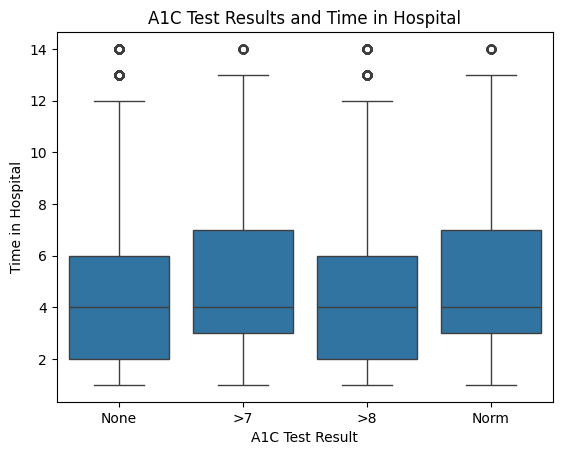

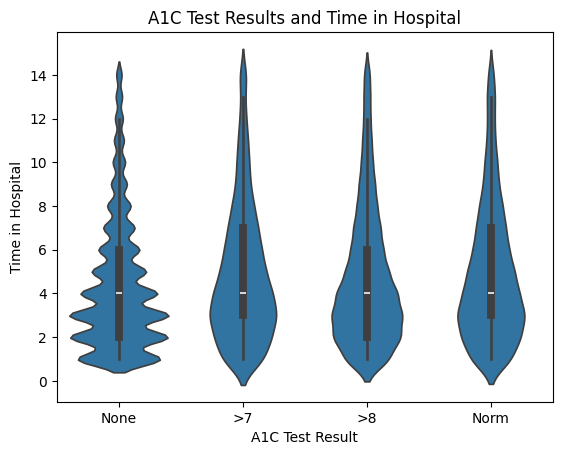

In [17]:
#Generating a plot for A1C tests and time in hospital
sns.boxplot(data=diabetic_data_4, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')

#Generating a violin plot
plt.figure()
sns.violinplot(data=diabetic_data_4, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')
plt.show()

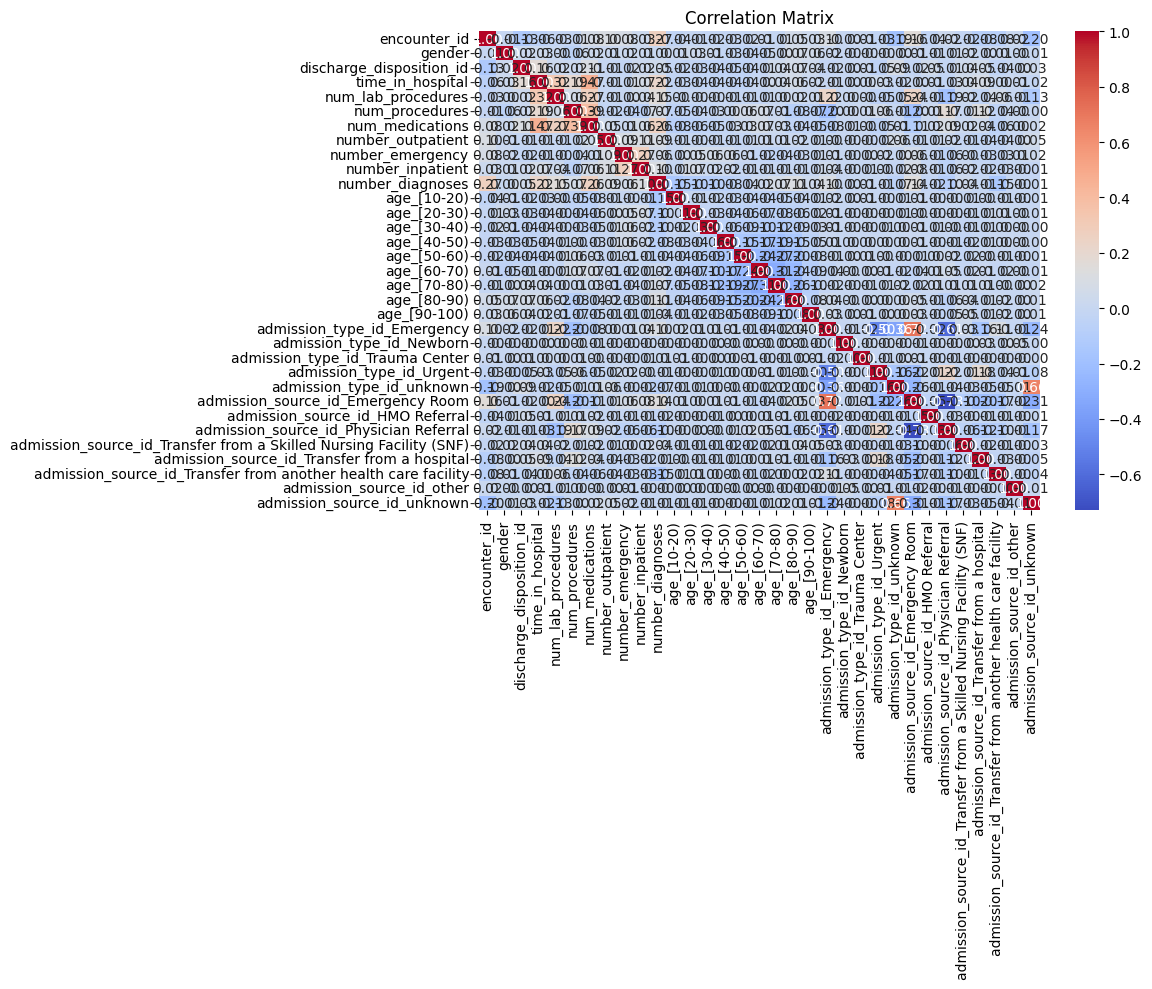

In [18]:
#Correlation Matrix
plt.figure(figsize=(12,10))
numeric_data = diabetic_data_4.select_dtypes(include='number').drop(columns='patient_nbr', errors='ignore')
correlation_matrix = numeric_data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_matrix.png')


/var/folders/t2/z2d0j1ns56l8gkc11rwm53pw0000gn/T/ipykernel_38771/1168845369.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(8,4))


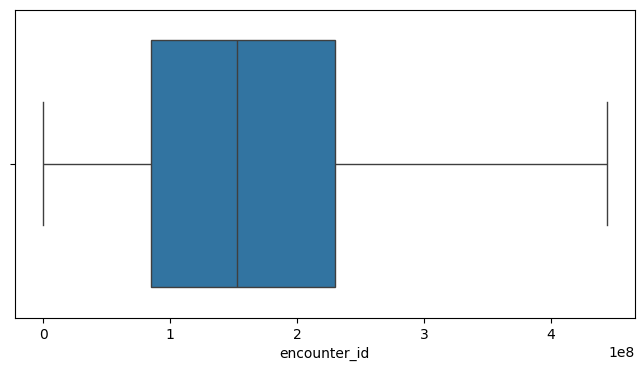

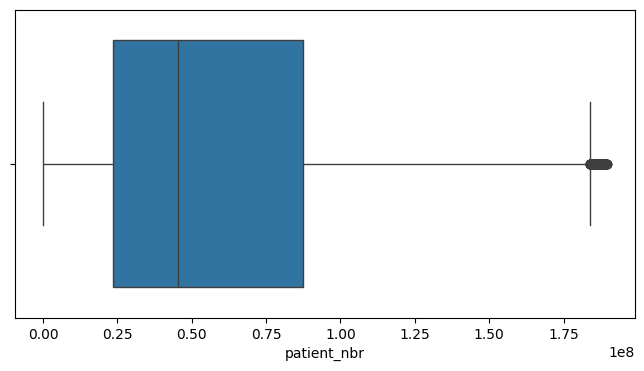

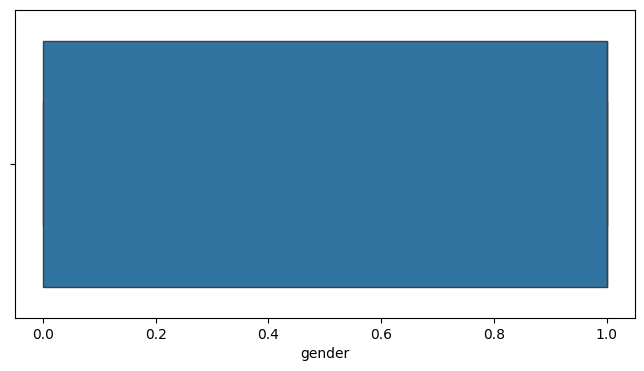

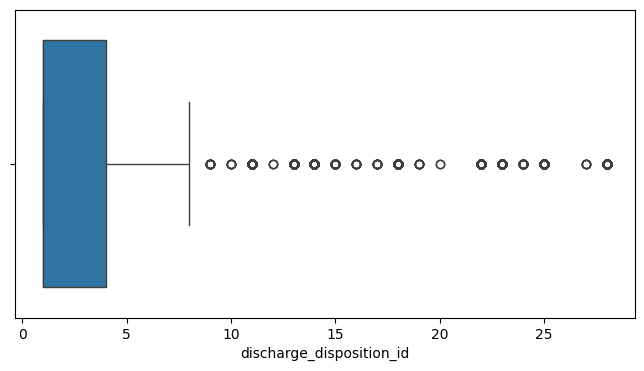

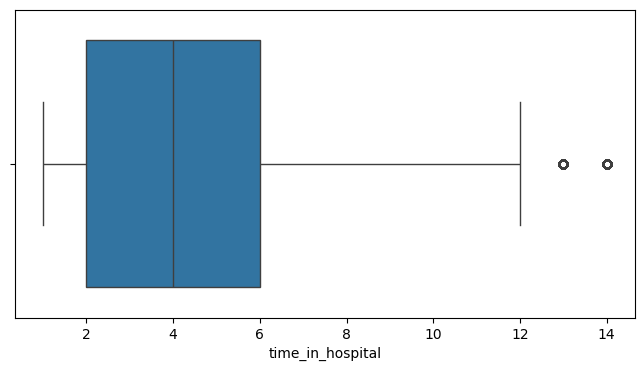

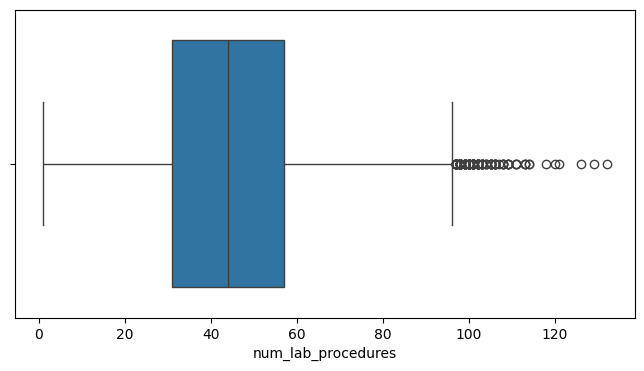

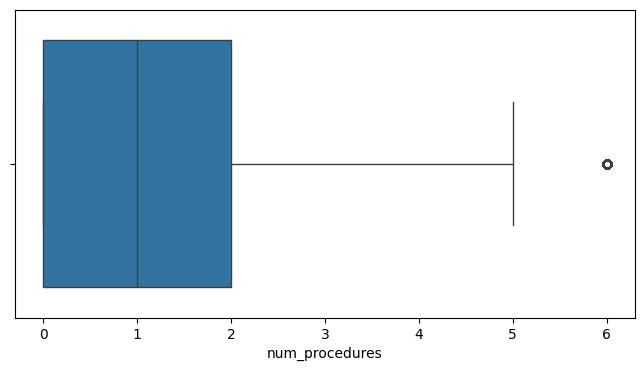

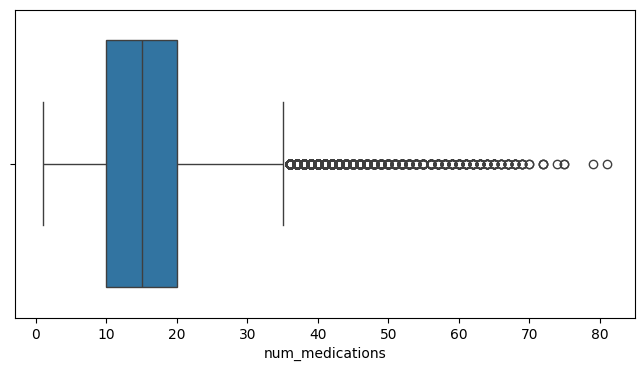

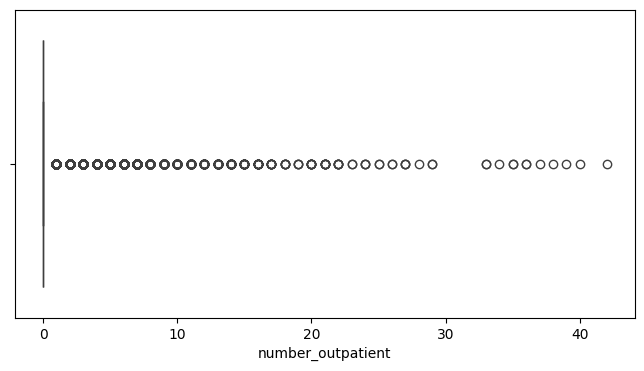

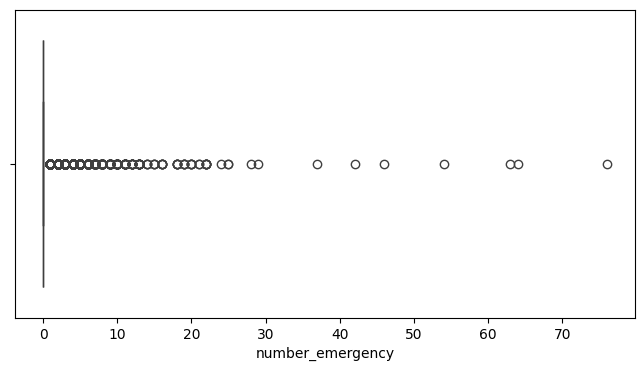

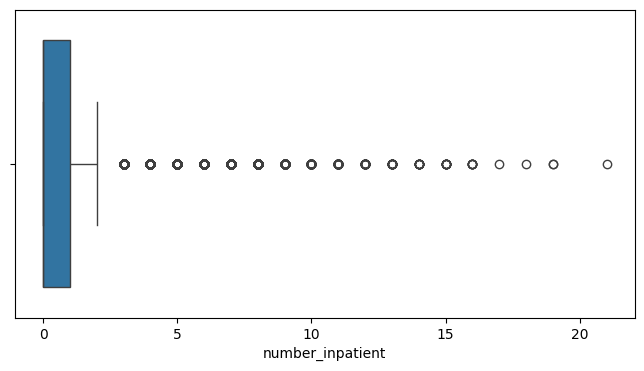

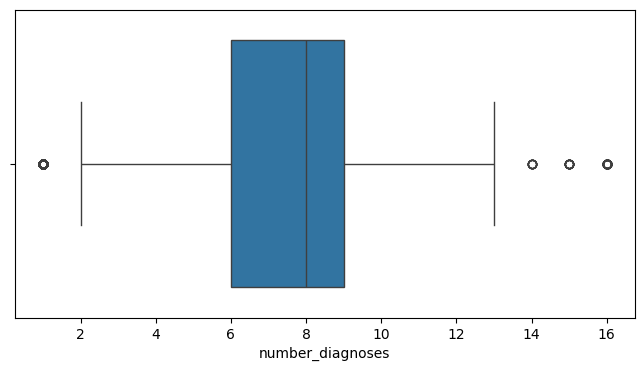

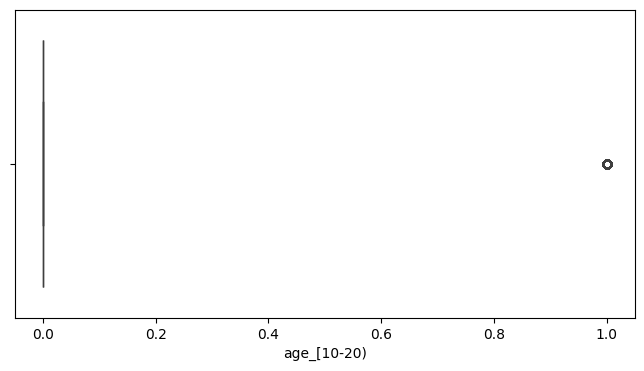

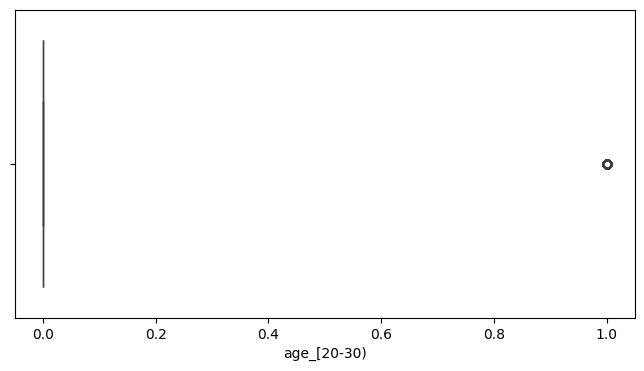

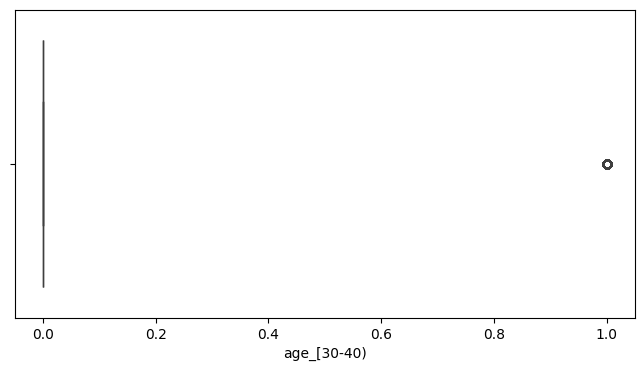

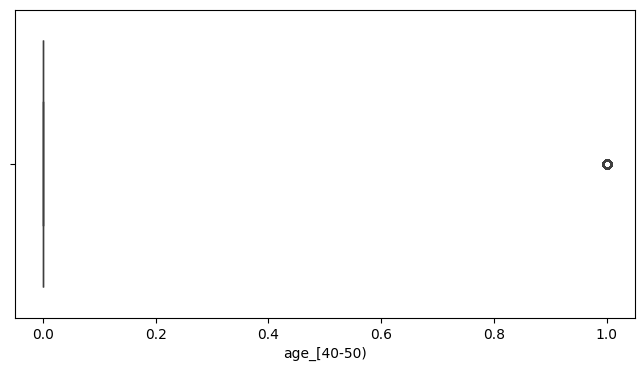

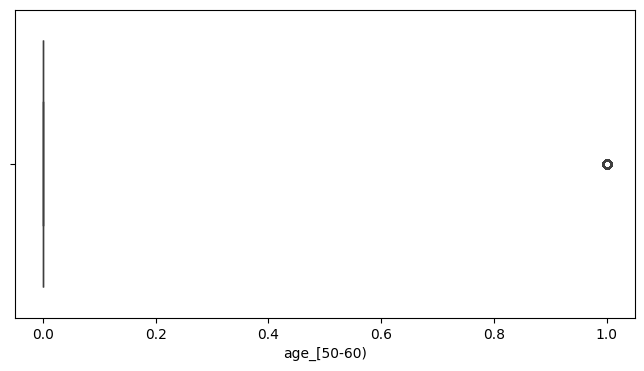

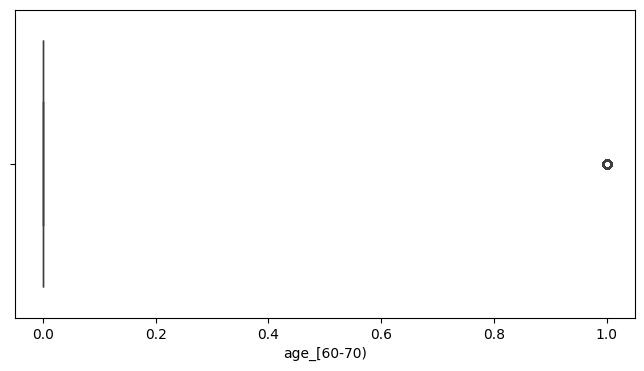

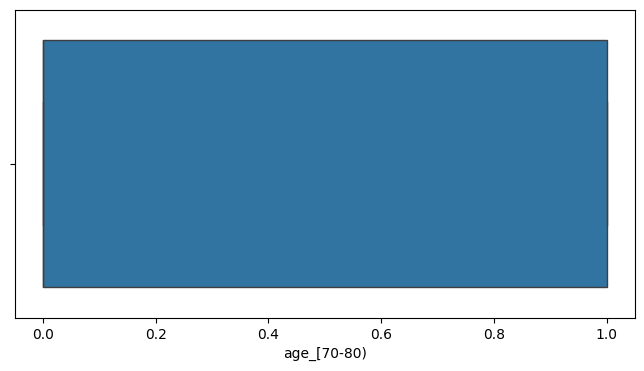

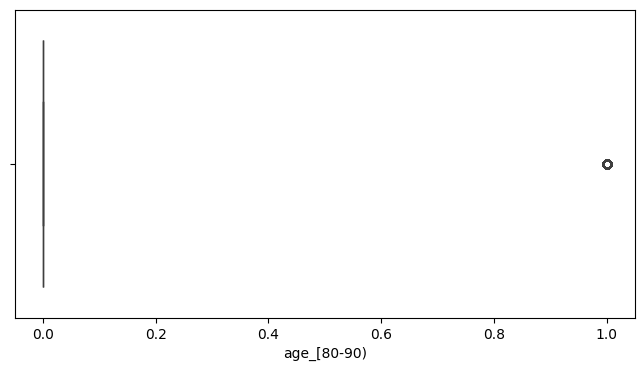

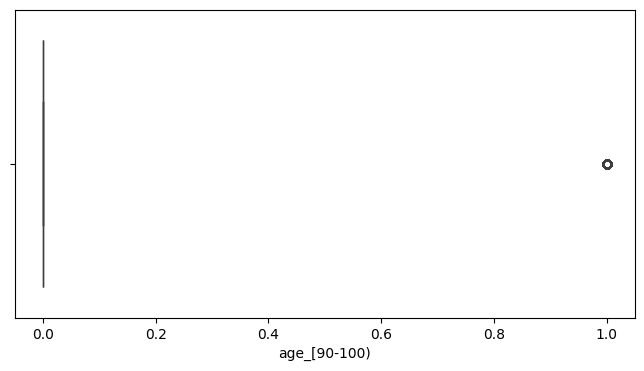

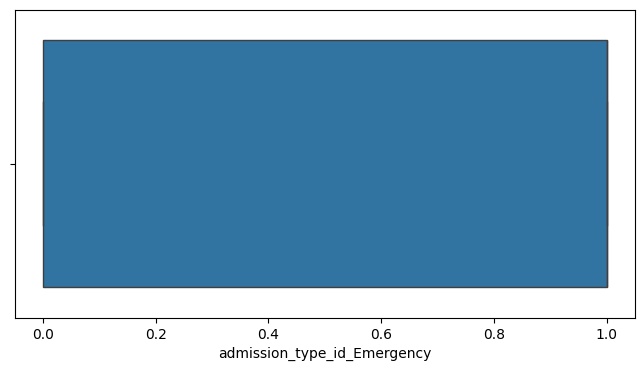

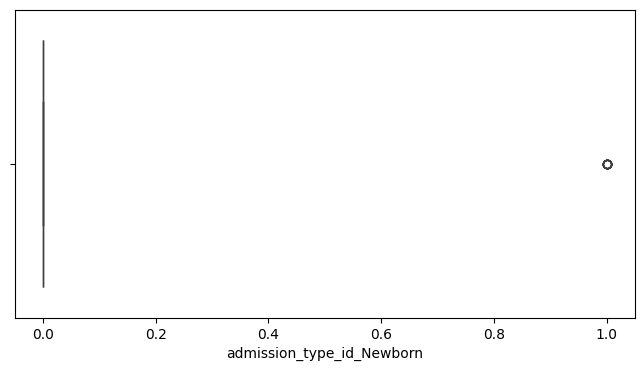

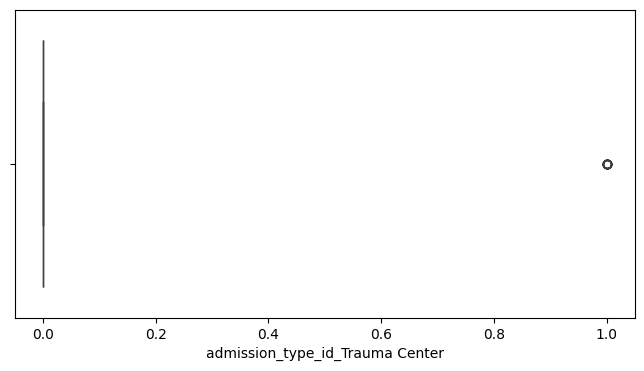

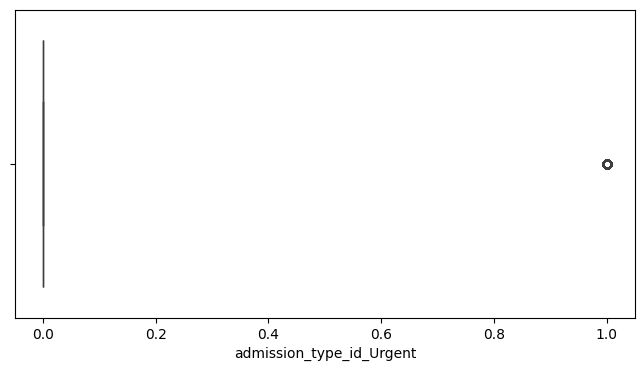

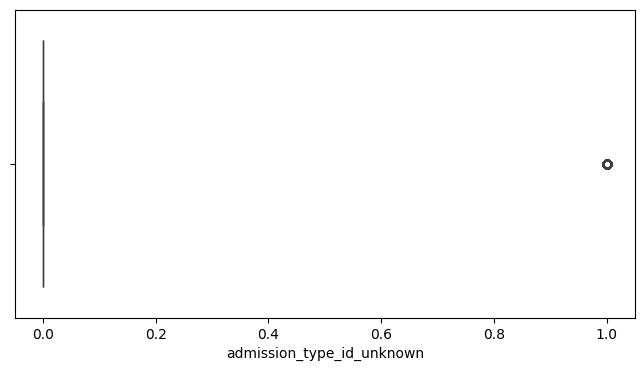

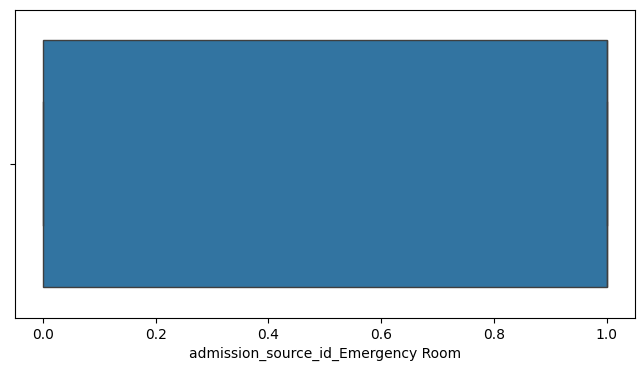

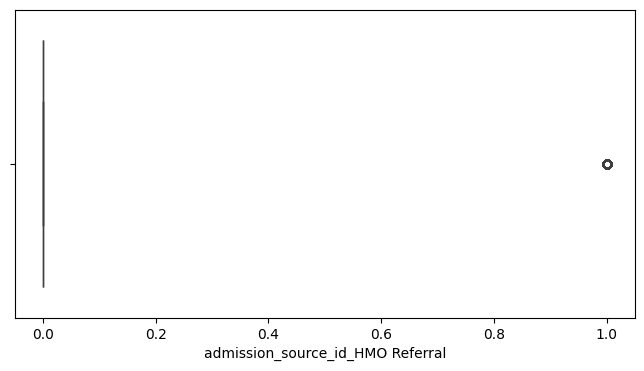

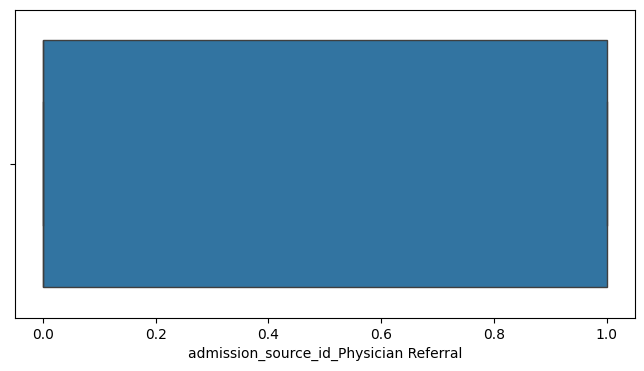

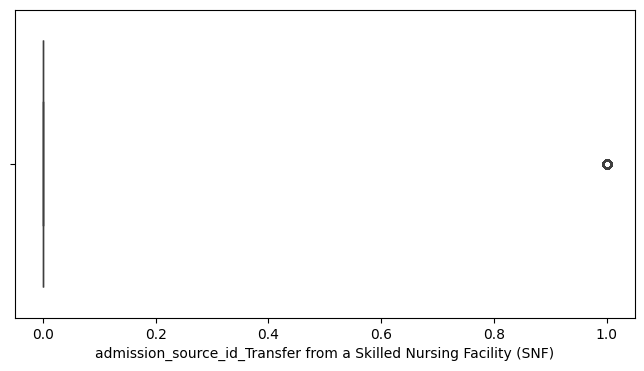

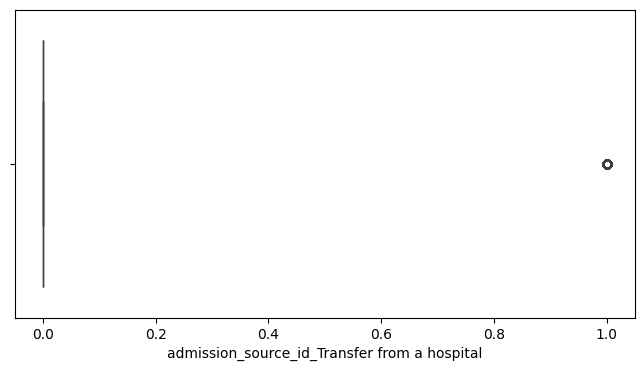

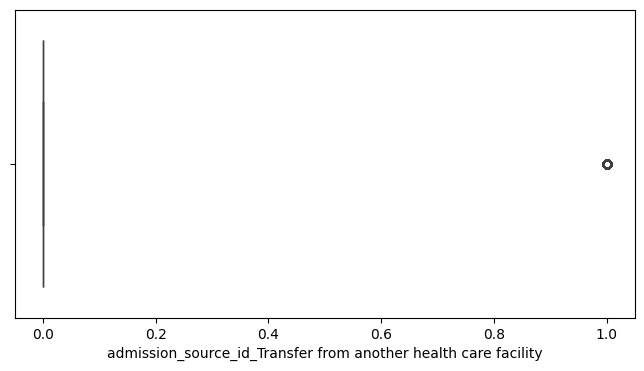

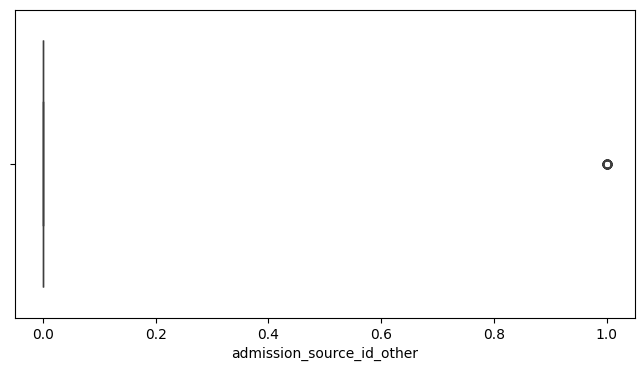

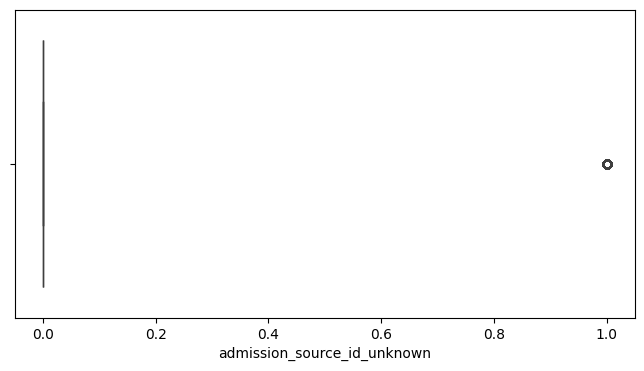

In [19]:
numerical_columns = diabetic_data_4.select_dtypes(
    include=['int64', 'float64']
).columns

for col in numerical_columns:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=diabetic_data_4[col])



<h1>Logistic Regression</h1>

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Split the data
# Predict A1C result from time in hospital
X = diabetic_data_4[['time_in_hospital']]
y = diabetic_data_4['A1Cresult']

# Remove rows with missing target values
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#Time in hospital based on a1c result

#Standardize
scaler = StandardScaler()

#Create train model
sk_model = LogisticRegression(max_iter=1000)
sk_model.fit(X_train, y_train)

#Make predictions
y_pred = sk_model.predict(X_test)
y_prob = sk_model.predict_proba(X_test)[:, 1]

#Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred))

#Plot Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()



ImportError: sklearn._cyutility does not export expected C function slice_memviewslice

# Visuals of univariate plots

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')


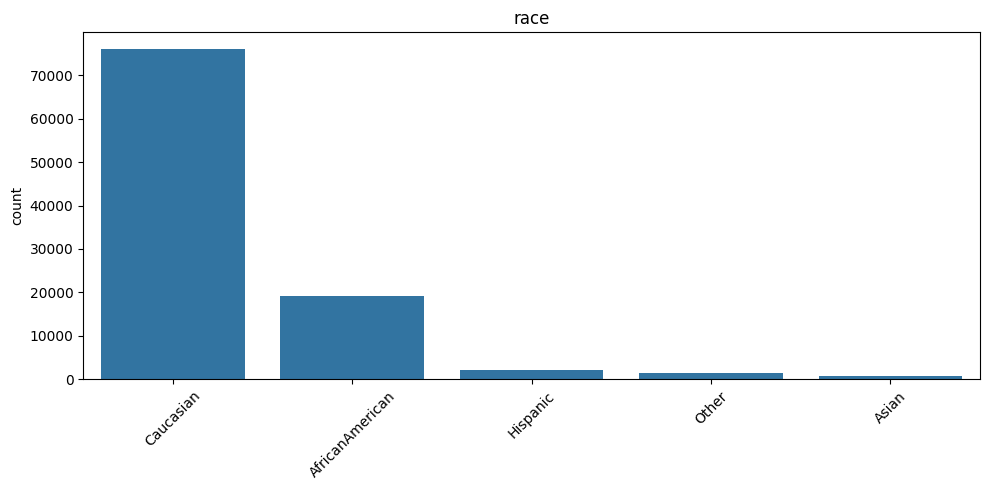

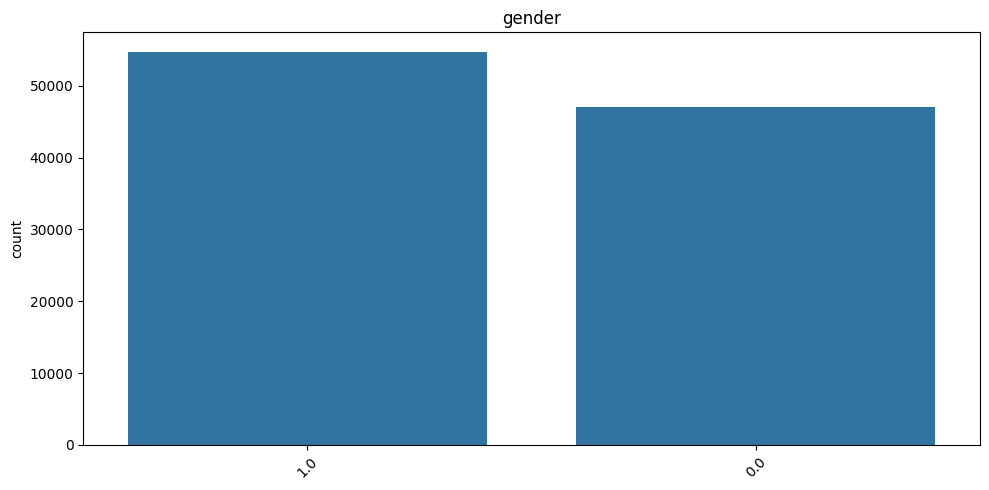

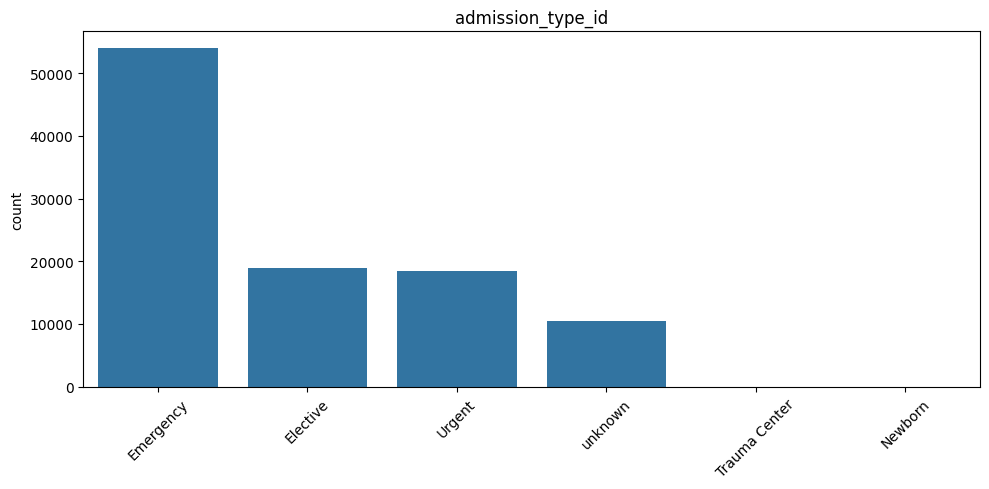

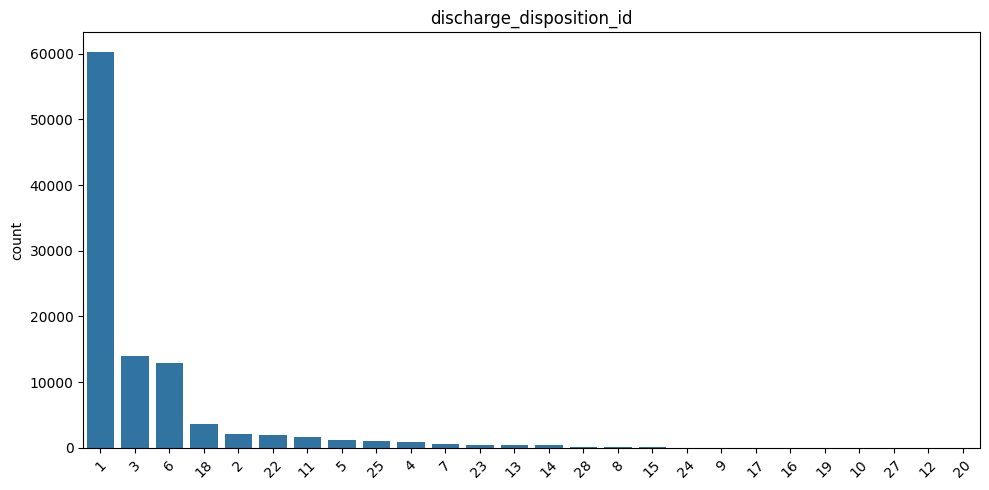

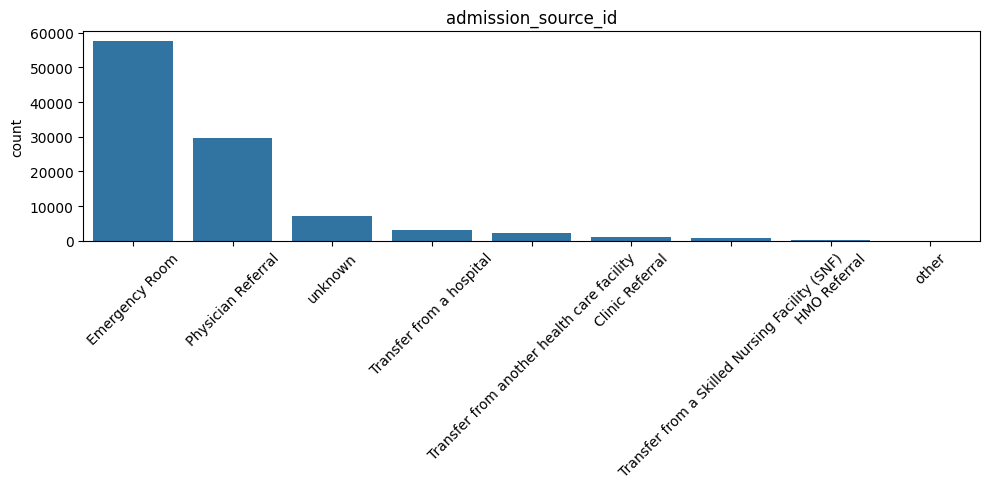

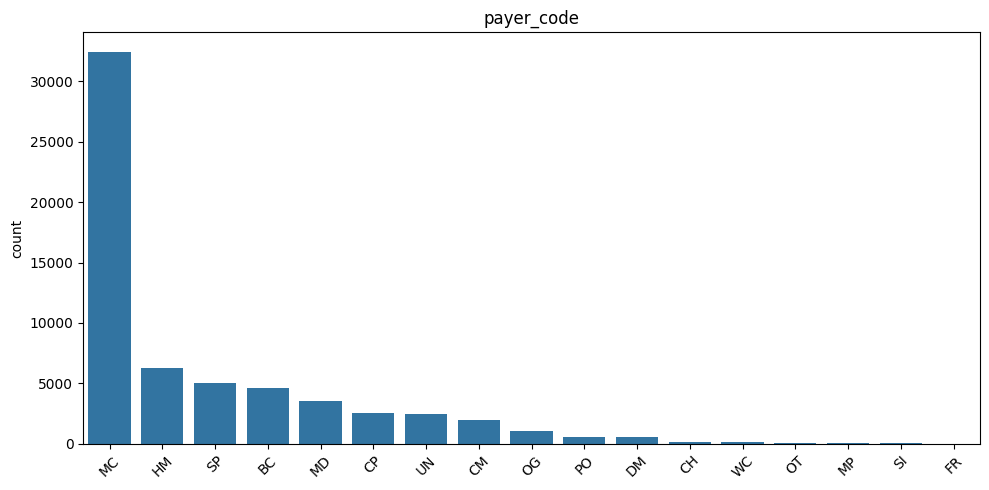

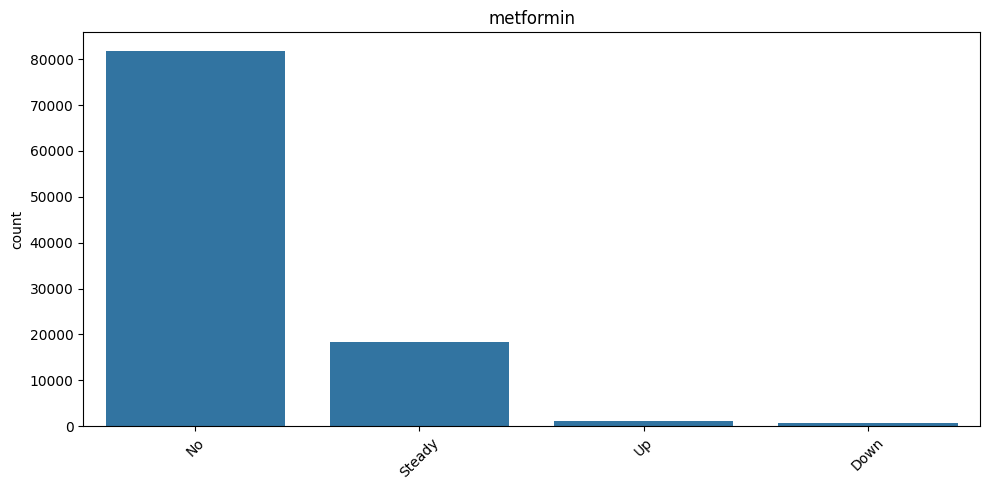

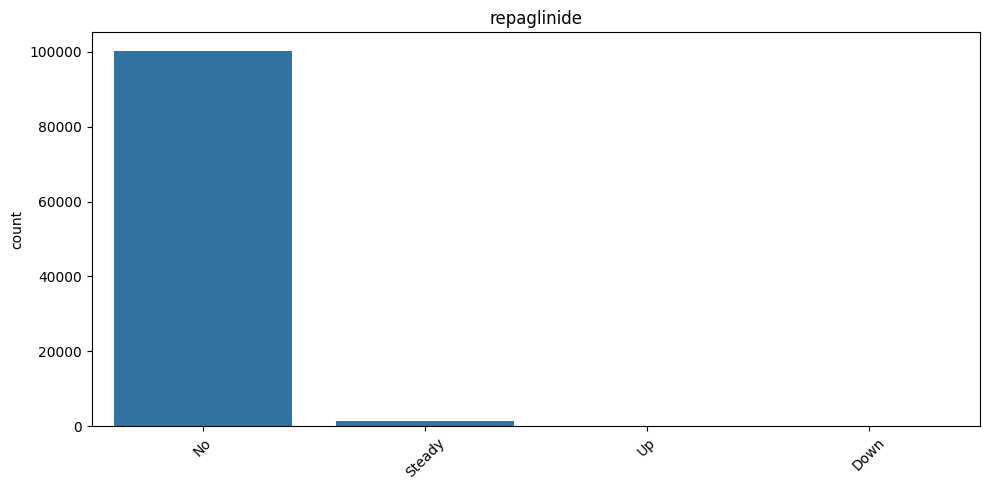

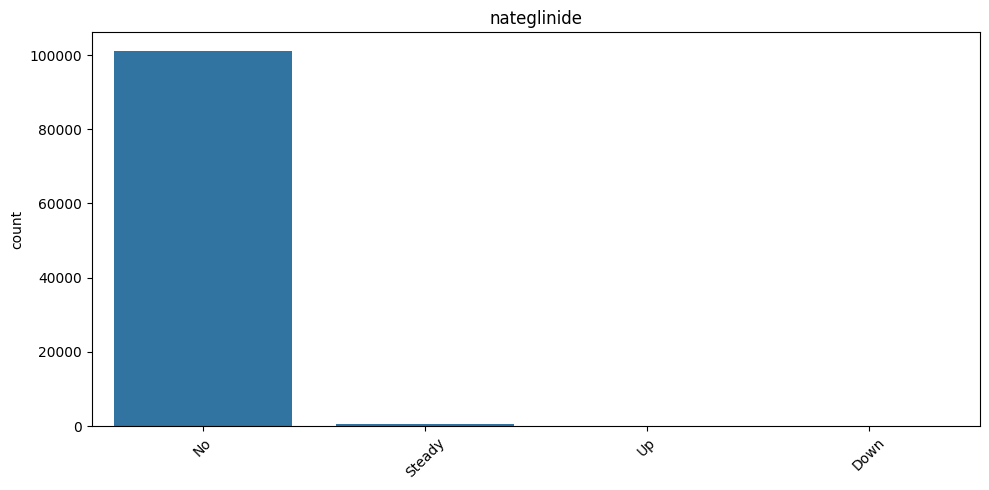

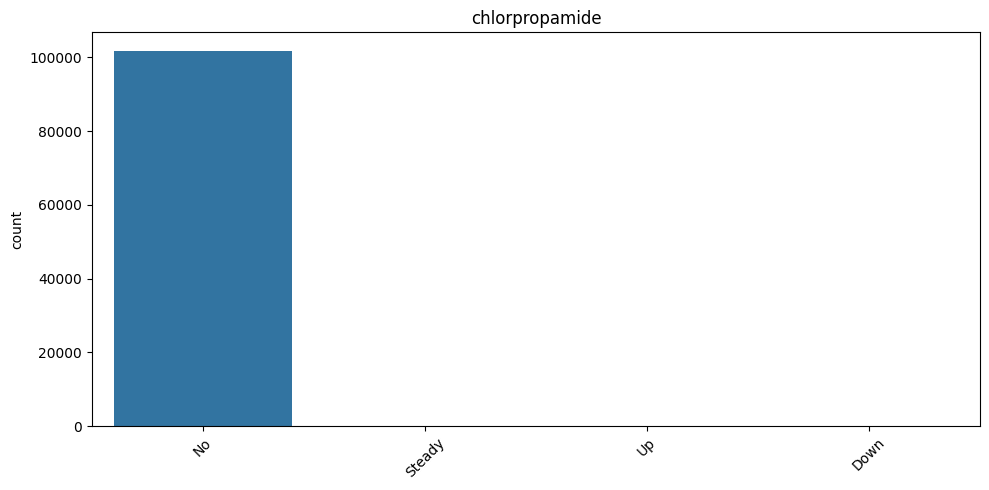

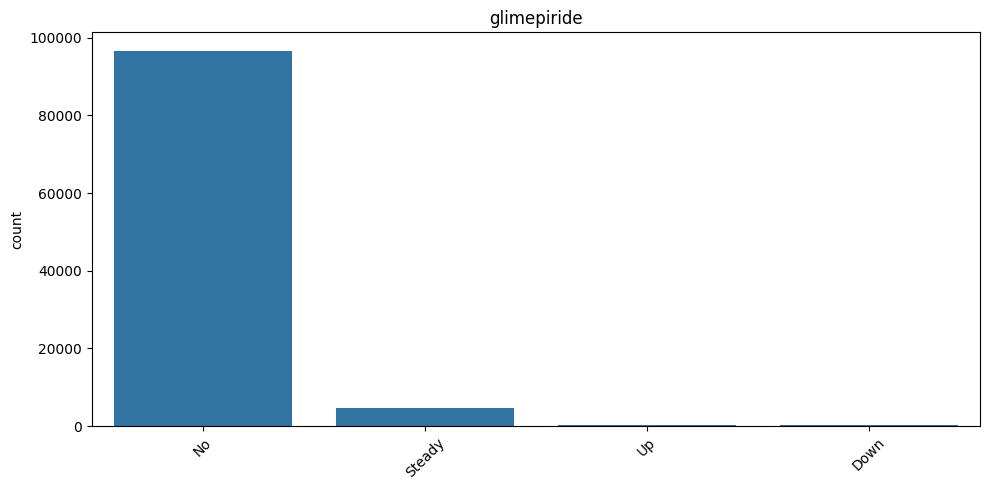

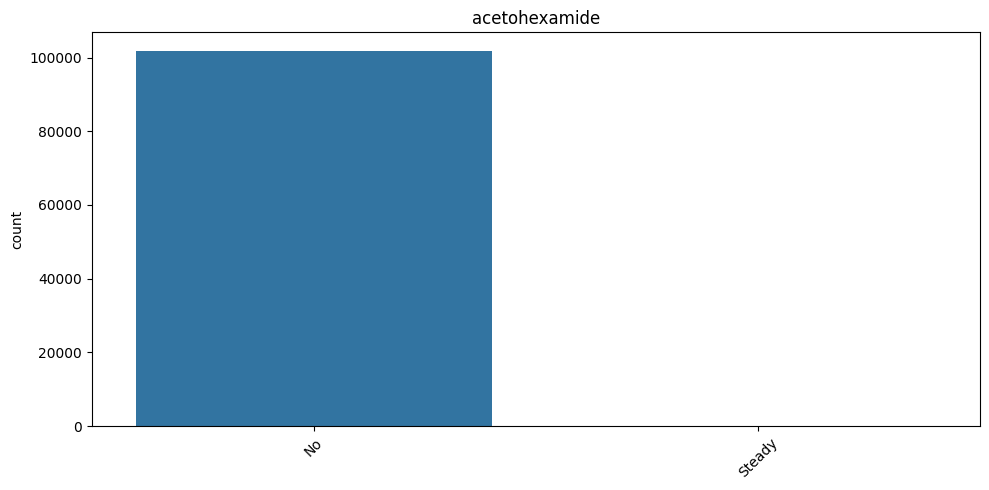

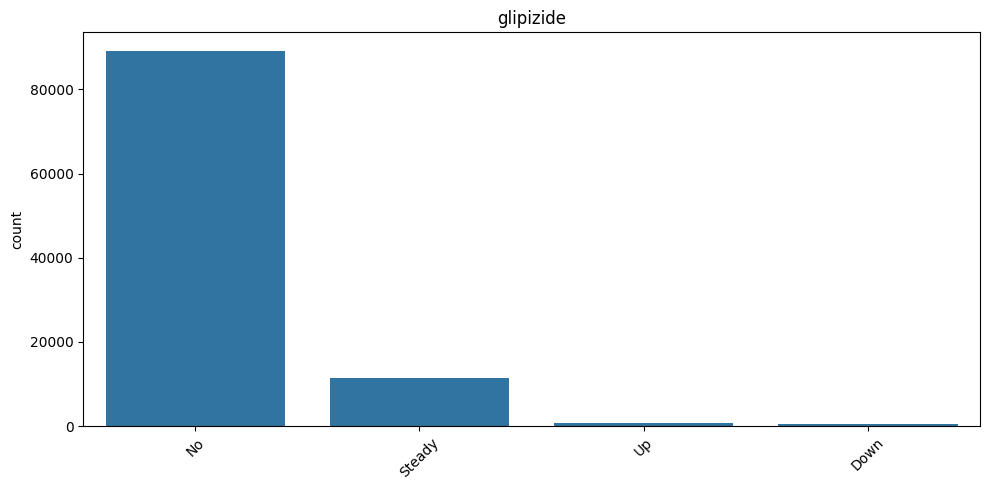

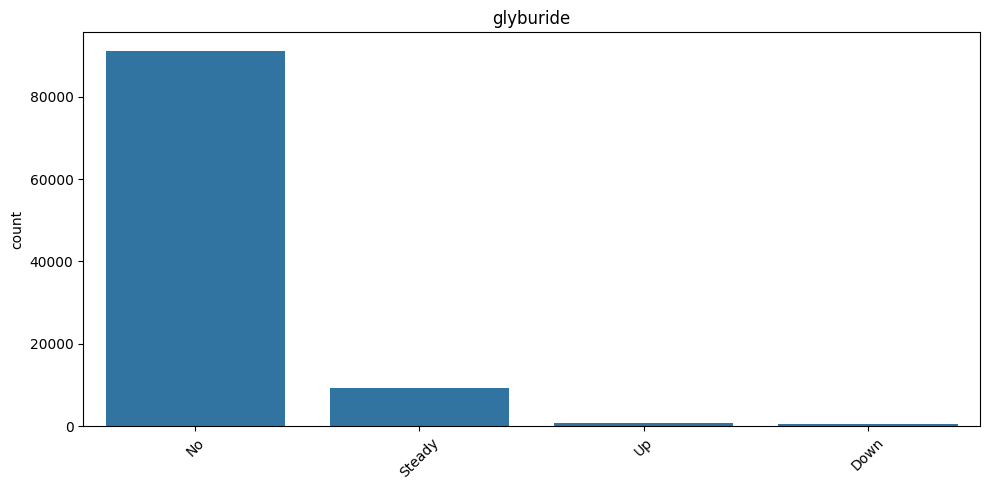

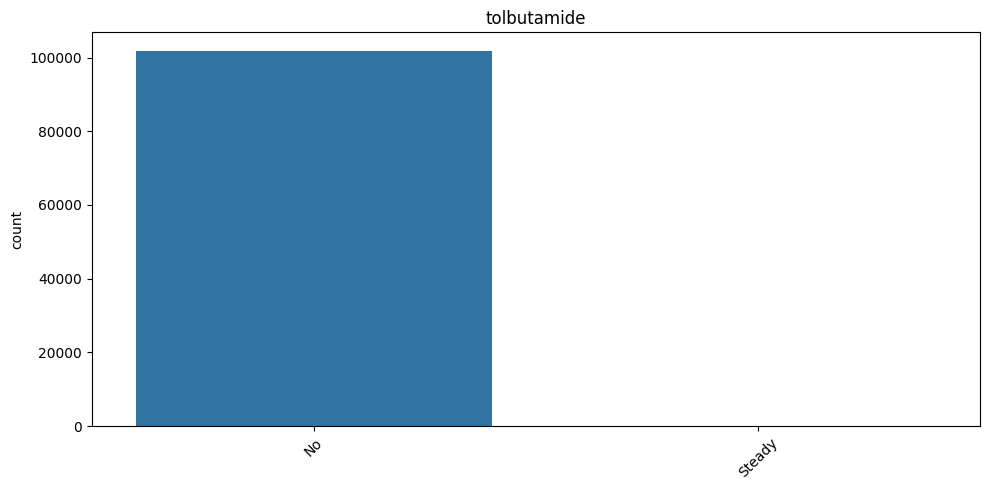

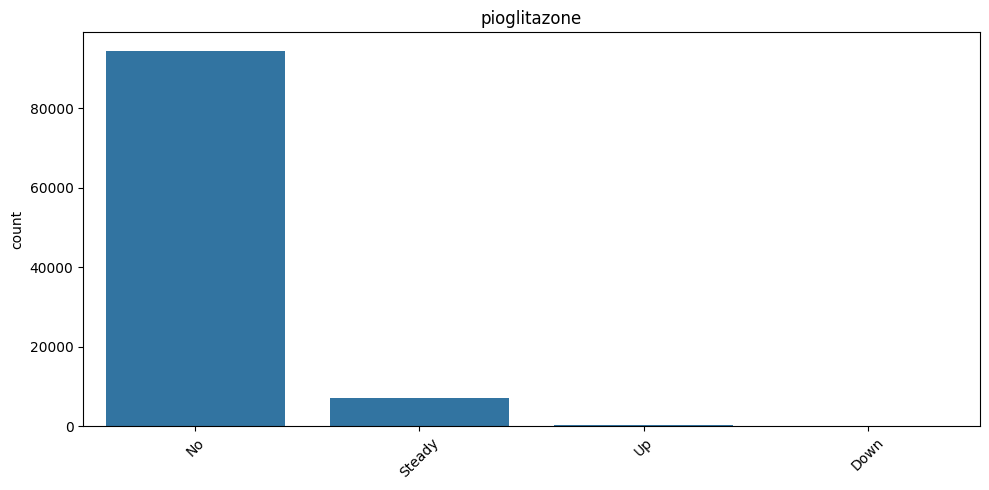

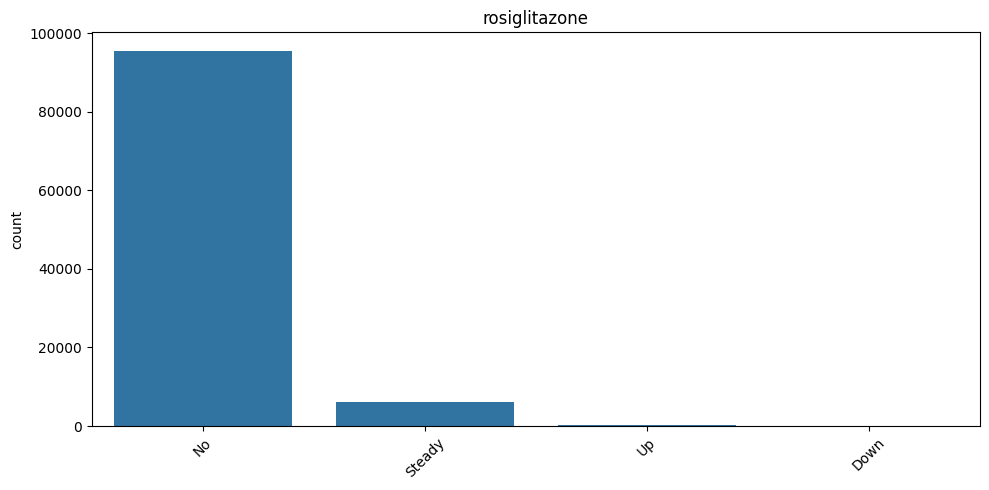

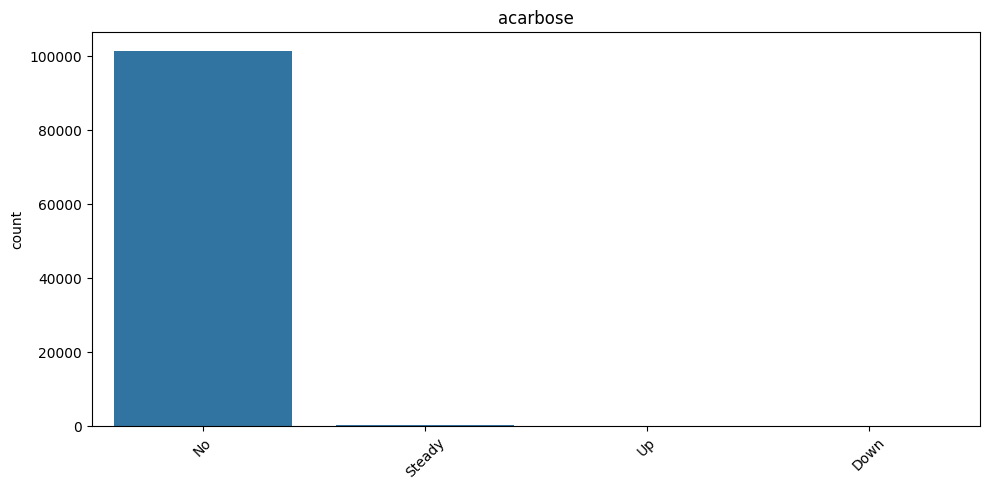

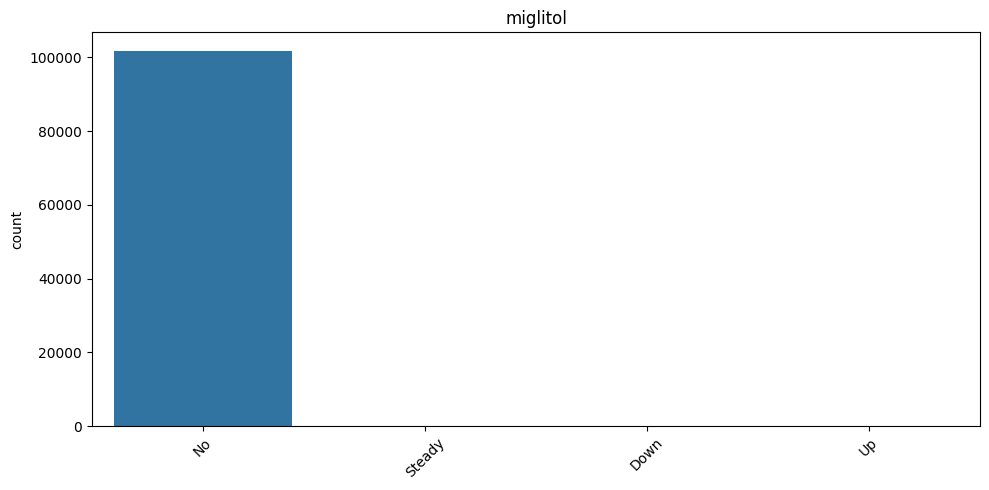

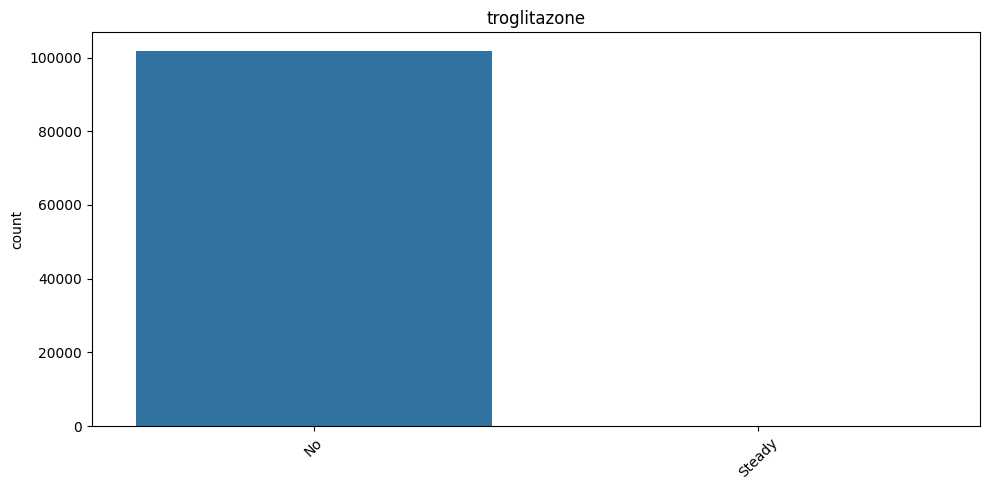

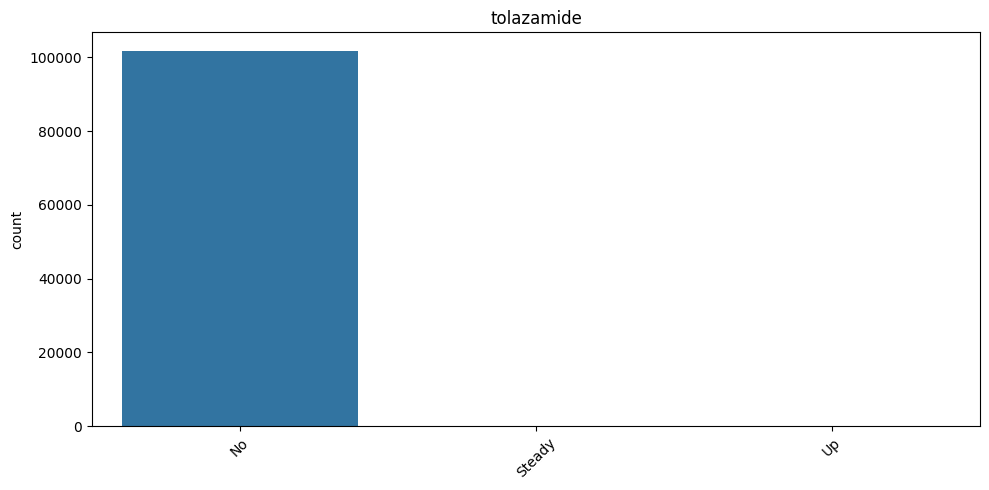

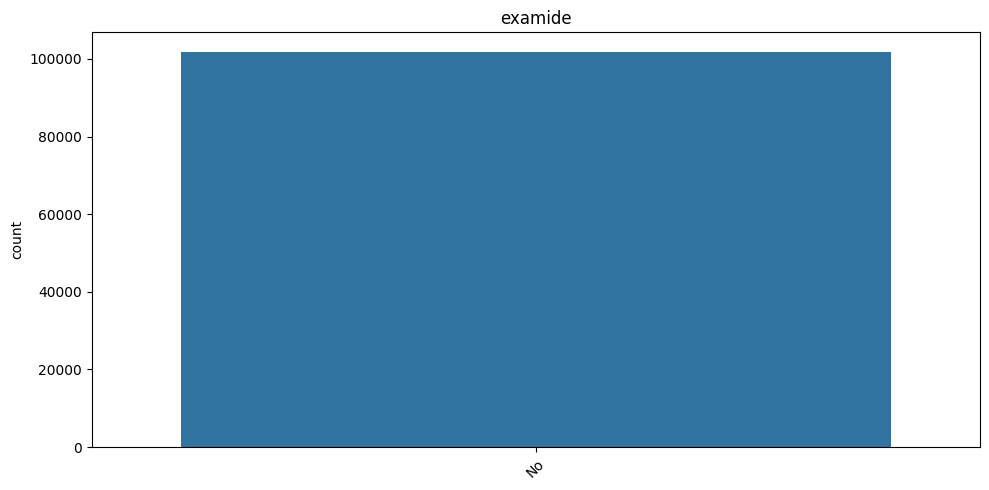

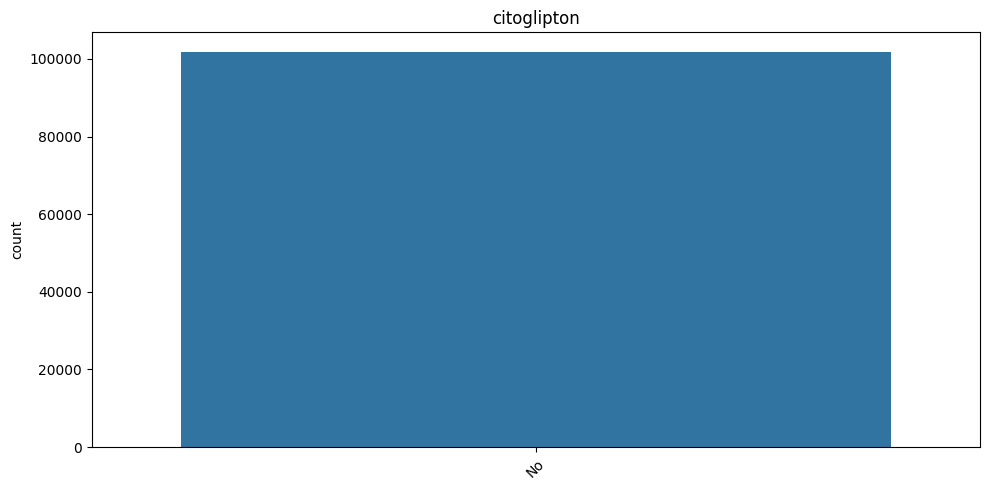

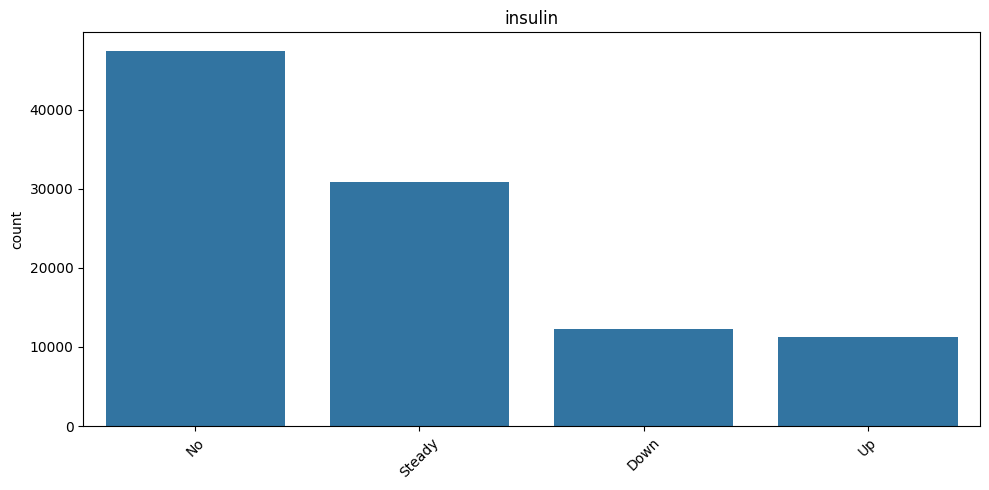

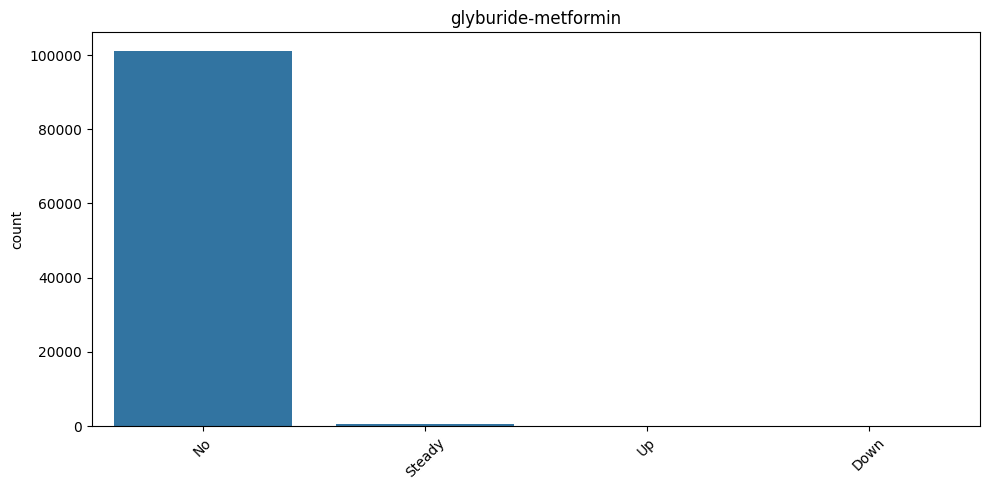

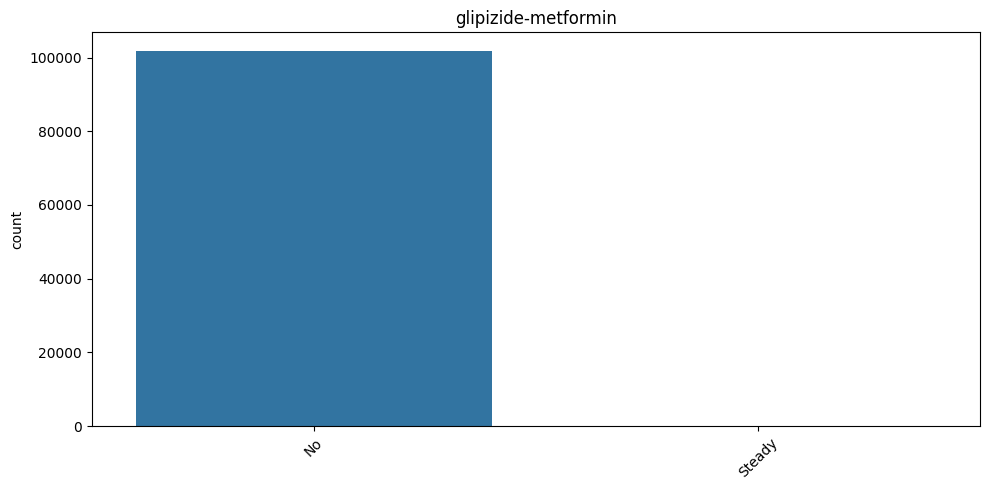

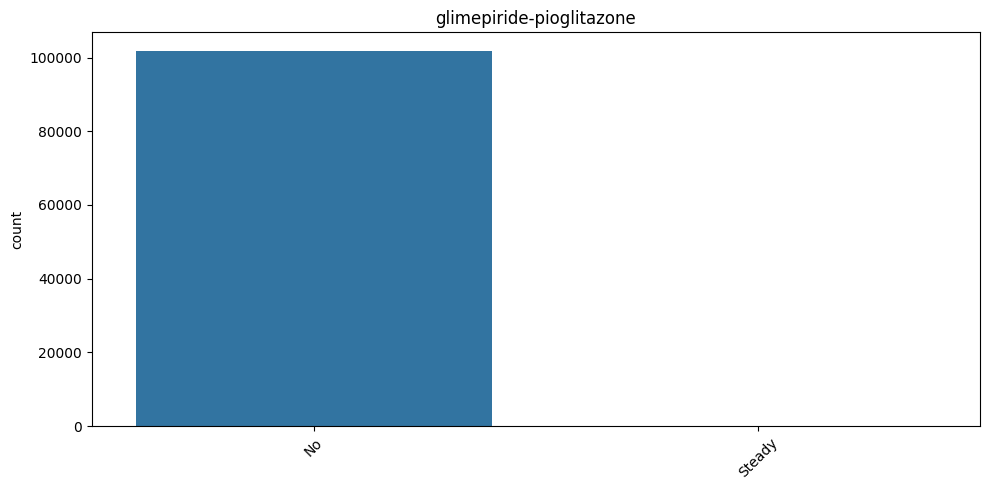

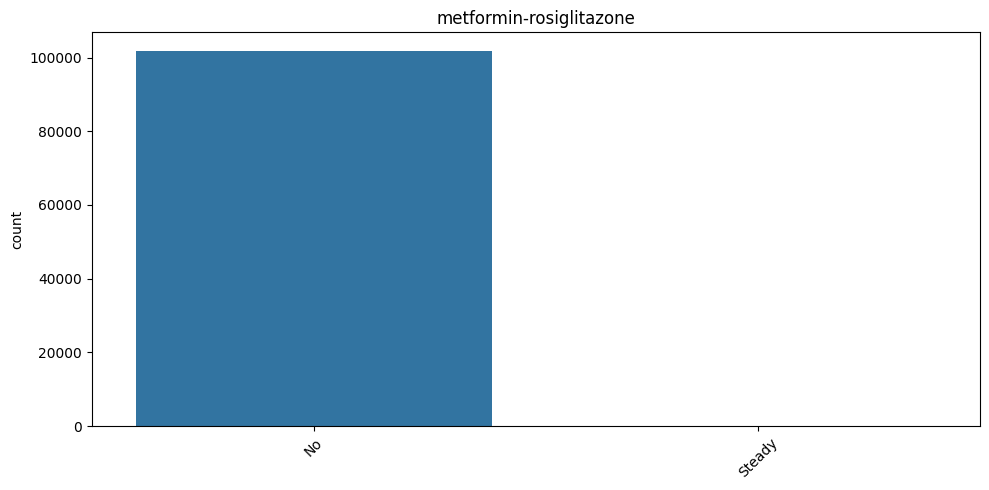

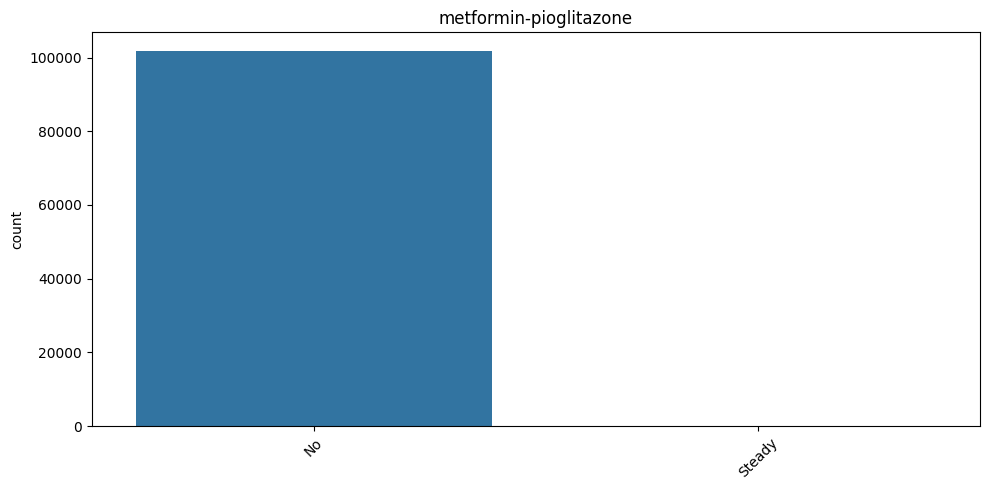

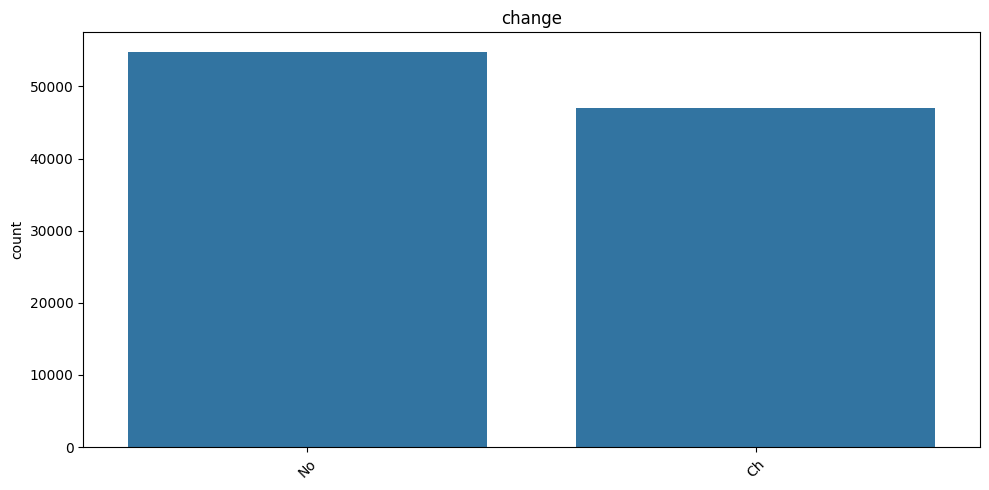

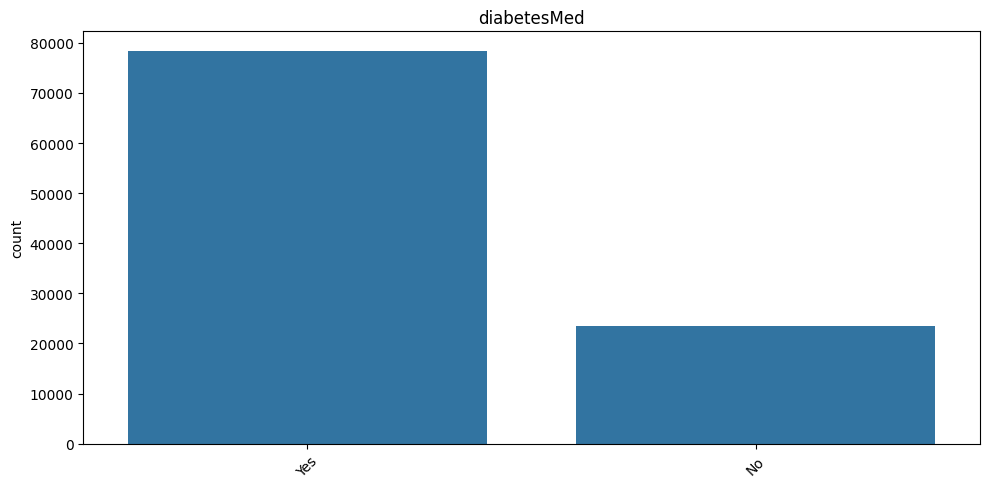

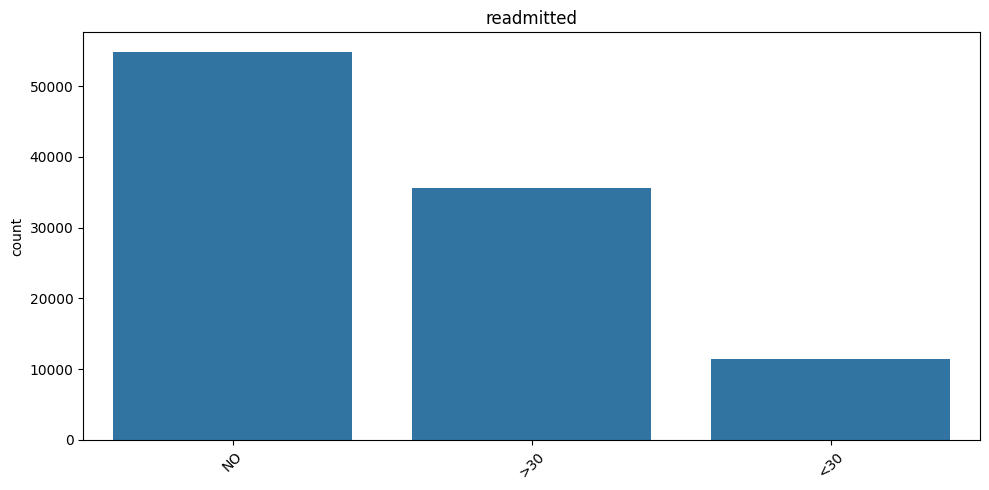

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['race', 'gender', 'admission_type_id', 'discharge_disposition_id',
        'admission_source_id', 'payer_code',
        'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
        'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
        'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
        'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin',
        'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone',
        'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

print(diabetic_data_4.columns)

for col in cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=diabetic_data_4, x=col, order=diabetic_data_4[col].value_counts().index)
    plt.title(col)
    plt.xlabel('')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()